<a href="https://colab.research.google.com/github/hilalkaynarcali/goruntu-isleme/blob/main/goruntu_isleme_multithreading_karsilastirma.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import cv2
import numpy as np
import threading
import time
import matplotlib.pyplot as plt

In [1]:
from google.colab import files
yuklenen = files.upload()
dosya_adi = list(yuklenen.keys())[0]
print("Yüklenen dosya:", dosya_adi)

Saving image2.jpeg to image2.jpeg
Yüklenen dosya: image2.jpeg


In [4]:
img = cv2.imread("image2.jpeg", 0)
print("Boyut:", img.shape)

Boyut: (1600, 1066)


In [5]:
h = img.shape[0]
parca = h // 4
degerler = [-40, 0, 40, 80]

for i in range(4):
    bas = i * parca
    son = (i + 1) * parca if i < 3 else h
    print("parça", i, ": satır", bas, "-", son, "| değişim:", degerler[i])

parça 0 : satır 0 - 400 | değişim: -40
parça 1 : satır 400 - 800 | değişim: 0
parça 2 : satır 800 - 1200 | değişim: 40
parça 3 : satır 1200 - 1600 | değişim: 80


In [6]:
sonuc = img.copy()

def parlaklik(i):
    bas = i * parca
    son = (i + 1) * parca if i < 3 else h
    bolge = img[bas:son].astype(np.int16) + degerler[i]
    sonuc[bas:son] = np.clip(bolge, 0, 255).astype(np.uint8)

threadler = []
for i in range(4):
    t = threading.Thread(target=parlaklik, args=(i,))
    threadler.append(t)
    t.start()

for t in threadler:
    t.join()

print("bitti")

bitti


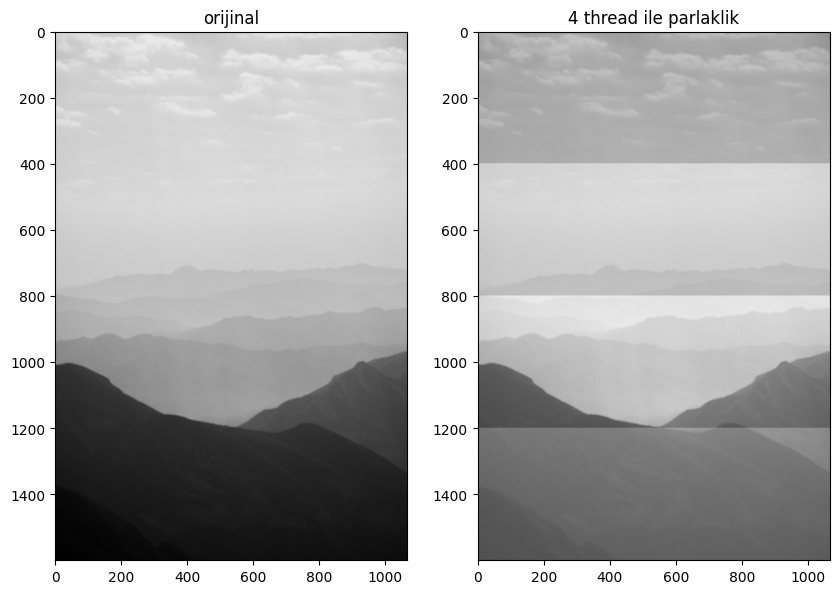

True

In [7]:
plt.figure(figsize=(10, 7))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("orijinal")

plt.subplot(1, 2, 2)
plt.imshow(sonuc, cmap="gray", vmin=0, vmax=255)
plt.title("4 thread ile parlaklik")

plt.show()
cv2.imwrite("sonuc_parlaklik.png", sonuc)

In [8]:
def isle(i, hedef):
    bas = i * parca
    son = (i + 1) * parca if i < 3 else h
    bolge = img[bas:son].astype(np.int16) + degerler[i]
    hedef[bas:son] = np.clip(bolge, 0, 255).astype(np.uint8)

def tek_thread():
    hedef = img.copy()
    for i in range(4):
        isle(i, hedef)
    return hedef

def dort_thread():
    hedef = img.copy()
    tl = [threading.Thread(target=isle, args=(i, hedef)) for i in range(4)]
    for t in tl:
        t.start()
    for t in tl:
        t.join()
    return hedef

tekrar = 50

baslangic = time.perf_counter()
for _ in range(tekrar):
    a = tek_thread()
t1 = (time.perf_counter() - baslangic) / tekrar

baslangic = time.perf_counter()
for _ in range(tekrar):
    b = dort_thread()
t4 = (time.perf_counter() - baslangic) / tekrar

print(f"1 thread : {t1*1000:.2f} ms")
print(f"4 thread : {t4*1000:.2f} ms")
print("Hızlanma :", round(t1 / t4, 2), "kat")
print("İki sonuç aynı mı:", np.array_equal(a, b))

1 thread : 0.73 ms
4 thread : 1.26 ms
Hızlanma : 0.58 kat
İki sonuç aynı mı: True
